# Import Libraries

In [93]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Import Data

In [94]:
train_df = pd.read_csv('data/raw/train.csv')

# Data Exploration

In [95]:
pd.set_option('display.max_columns',None)

In [96]:
train_df.head()

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


In [97]:
train_df.shape

(2666, 20)

#

In [98]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2666 entries, 0 to 2665
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   State                   2666 non-null   str    
 1   Account length          2666 non-null   int64  
 2   Area code               2666 non-null   int64  
 3   International plan      2666 non-null   str    
 4   Voice mail plan         2666 non-null   str    
 5   Number vmail messages   2666 non-null   int64  
 6   Total day minutes       2666 non-null   float64
 7   Total day calls         2666 non-null   int64  
 8   Total day charge        2666 non-null   float64
 9   Total eve minutes       2666 non-null   float64
 10  Total eve calls         2666 non-null   int64  
 11  Total eve charge        2666 non-null   float64
 12  Total night minutes     2666 non-null   float64
 13  Total night calls       2666 non-null   int64  
 14  Total night charge      2666 non-null   float64
 15

# EDA

In [99]:
train_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Account length,2666.0,100.620405,39.563974,1.00,73.0000,100.00,127.000,243.00
Area code,2666.0,437.438860,42.521018,408.00,408.0000,415.00,510.000,510.00
Number vmail messages,2666.0,8.021755,13.612277,0.00,0.0000,0.00,19.000,50.00
Total day minutes,2666.0,179.481620,54.210350,0.00,143.4000,179.95,215.900,350.80
Total day calls,2666.0,100.310203,19.988162,0.00,87.0000,101.00,114.000,160.00
Total day charge,2666.0,30.512404,9.215733,0.00,24.3800,30.59,36.700,59.64
Total eve minutes,2666.0,200.386159,50.951515,0.00,165.3000,200.90,235.100,363.70
Total eve calls,2666.0,100.023631,20.161445,0.00,87.0000,100.00,114.000,170.00
Total eve charge,2666.0,17.033072,4.330864,0.00,14.0500,17.08,19.980,30.91
Total night minutes,2666.0,201.168942,50.780323,43.70,166.9250,201.15,236.475,395.00


In [100]:
num = train_df.select_dtypes(include=[np.number]).columns.tolist()

In [101]:
len(num)

16

In [102]:
plt.rcParams['figure.figsize'] = [20,10]

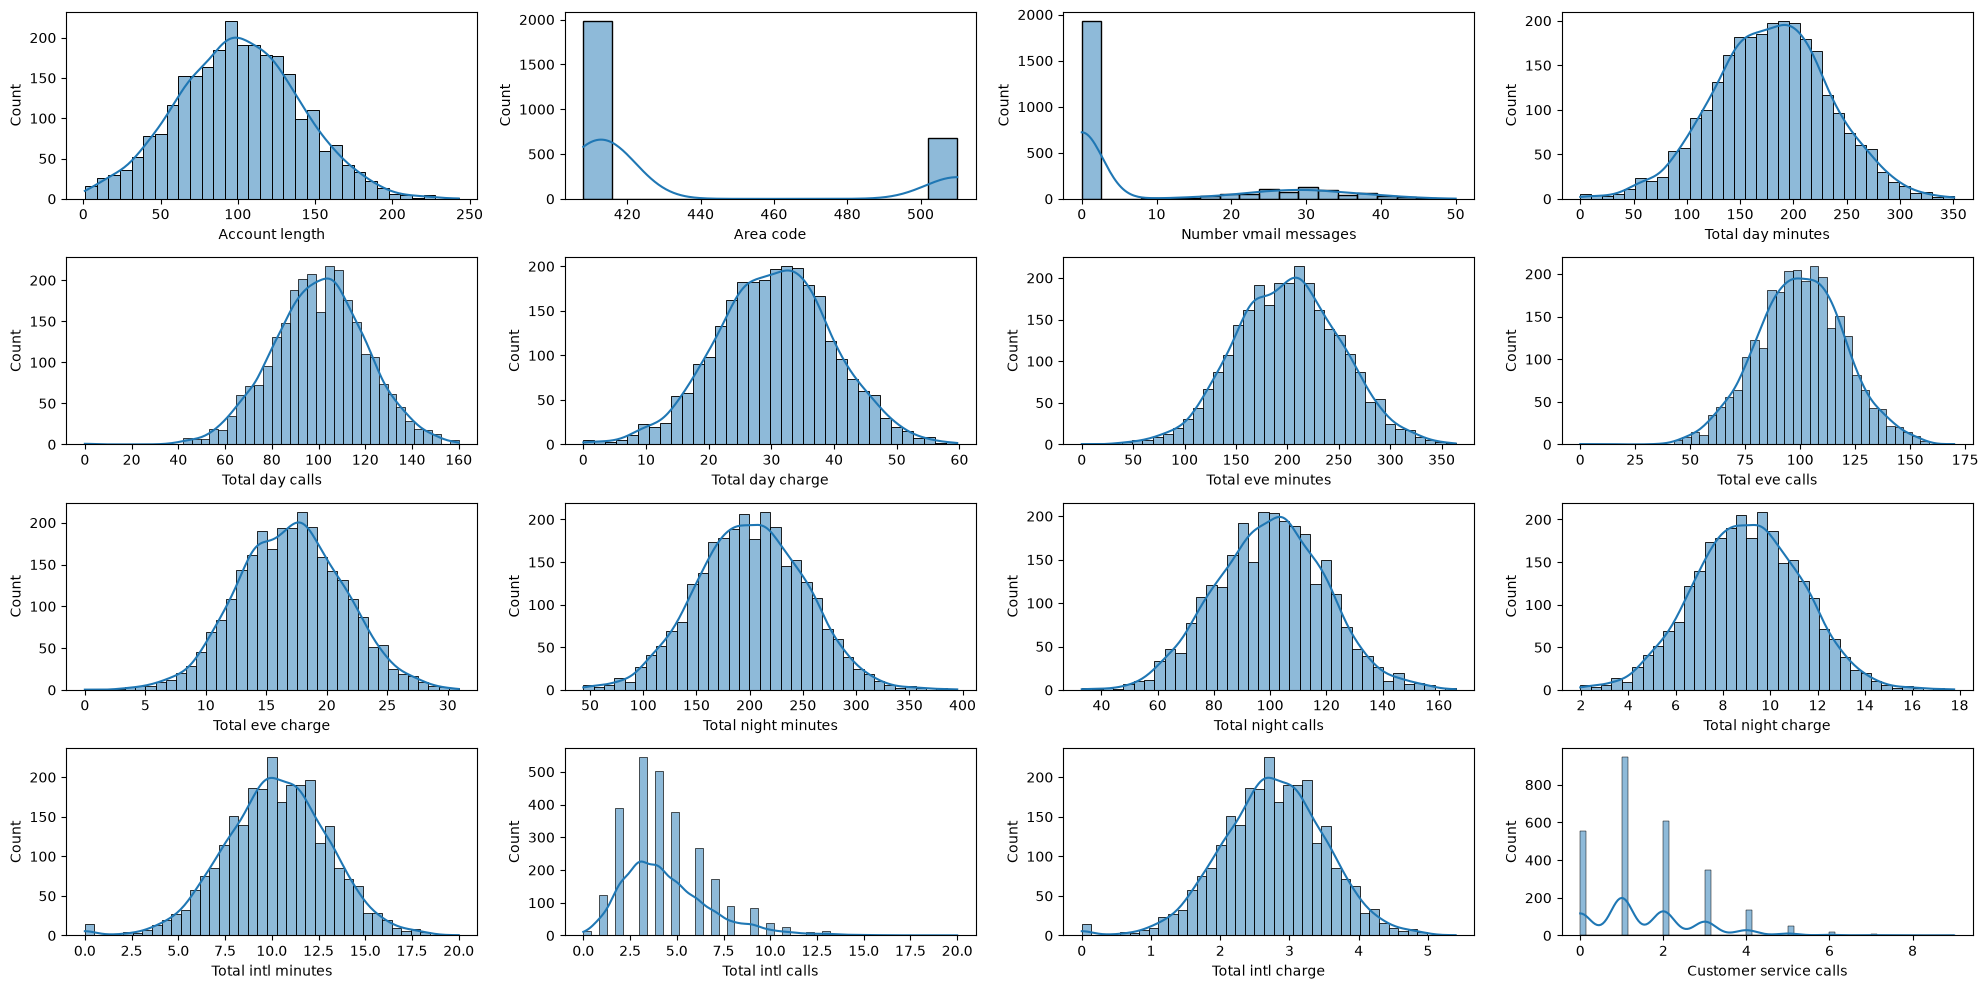

In [103]:
t = 1
for col in num:
    plt.subplot(4,4,t)
    sns.histplot(train_df[col],kde=True)
    t+=1
plt.tight_layout()
plt.show()

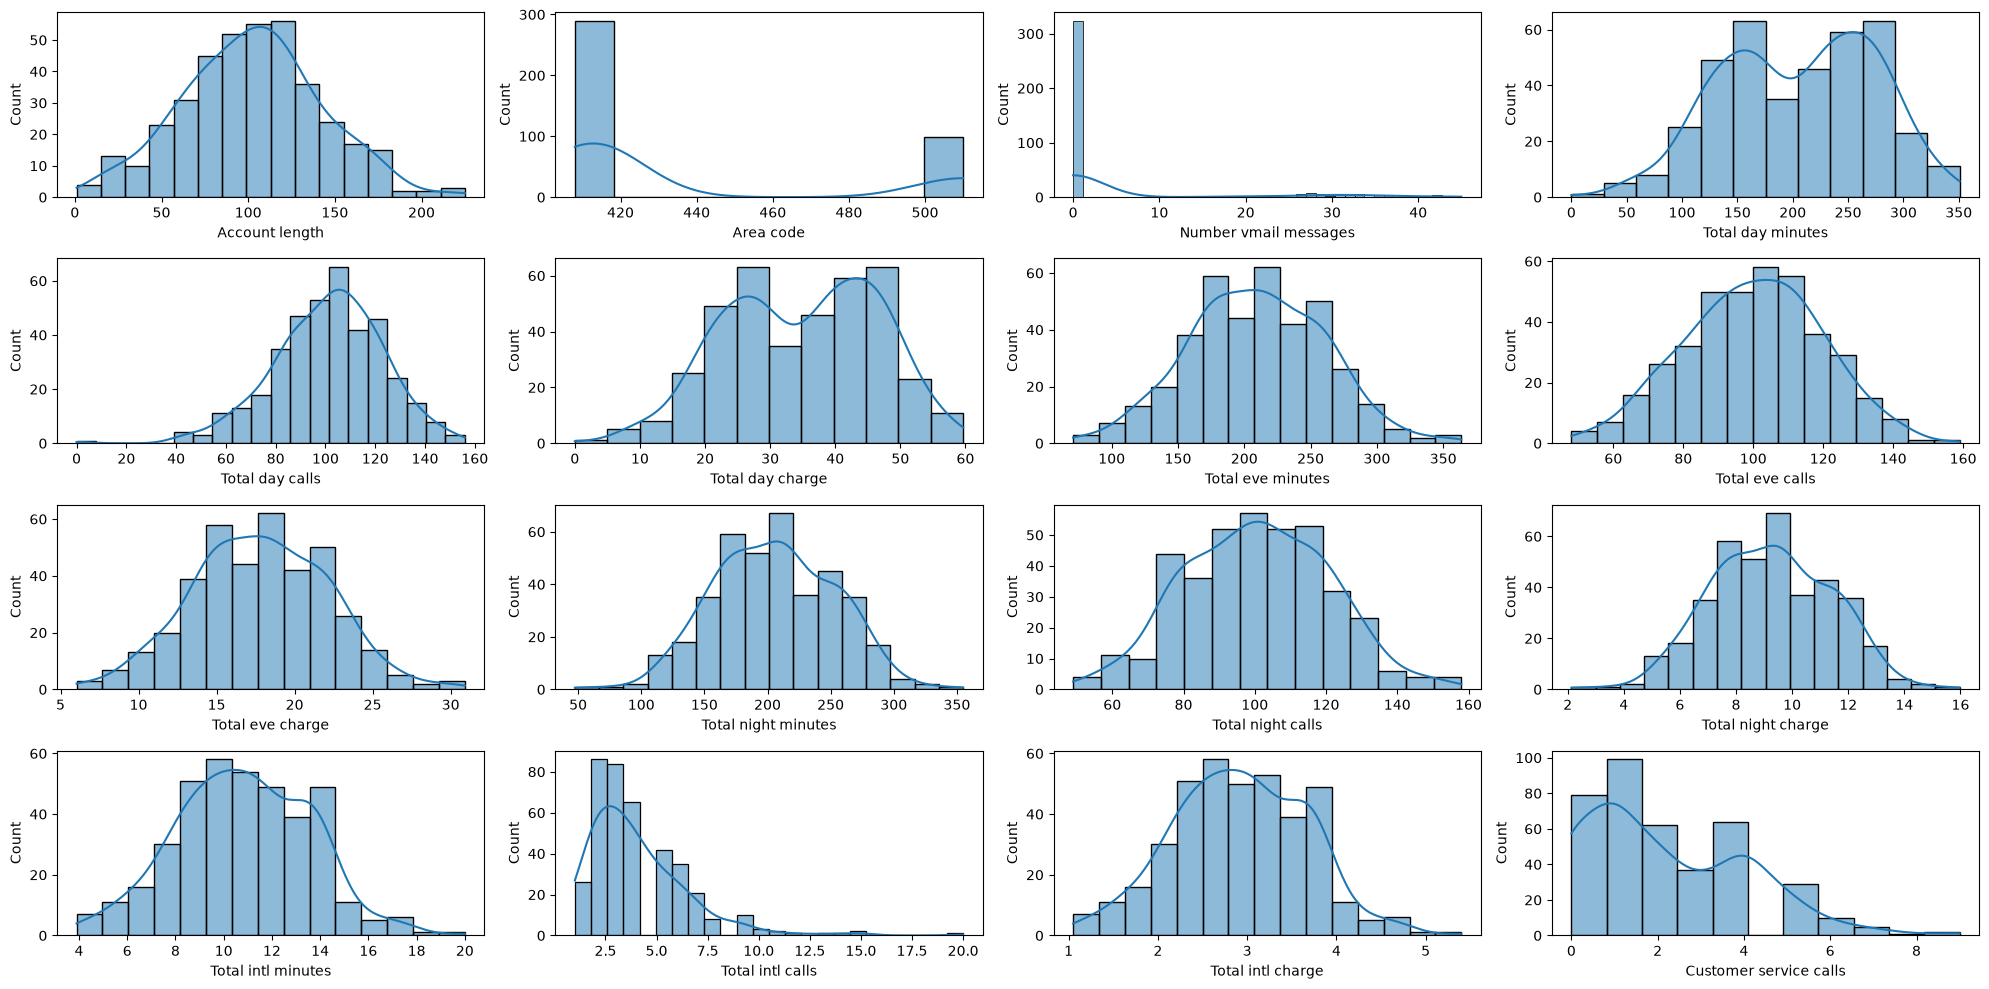

In [104]:
t = 1
for col in num:
    plt.subplot(4,4,t)
    sns.histplot(train_df[train_df['Churn']==True][col],kde=True)
    t+=1
plt.tight_layout()
plt.show()

In [105]:
for col in num:
    print(f"Skewness of {col} for those who churn is {round(train_df[col].skew(),2)}")

Skewness of Account length for those who churn is 0.08
Skewness of Area code for those who churn is 1.11
Skewness of Number vmail messages for those who churn is 1.27
Skewness of Total day minutes for those who churn is -0.05
Skewness of Total day calls for those who churn is -0.13
Skewness of Total day charge for those who churn is -0.05
Skewness of Total eve minutes for those who churn is -0.01
Skewness of Total eve calls for those who churn is -0.07
Skewness of Total eve charge for those who churn is -0.01
Skewness of Total night minutes for those who churn is 0.02
Skewness of Total night calls for those who churn is 0.01
Skewness of Total night charge for those who churn is 0.02
Skewness of Total intl minutes for those who churn is -0.22
Skewness of Total intl calls for those who churn is 1.36
Skewness of Total intl charge for those who churn is -0.22
Skewness of Customer service calls for those who churn is 1.1


In [106]:
for col in num:
    print(f"Skewness of {col} for those who churn is {round(train_df[train_df['Churn']==True][col].skew(),2)}")

Skewness of Account length for those who churn is 0.09
Skewness of Area code for those who churn is 1.11
Skewness of Number vmail messages for those who churn is 2.0
Skewness of Total day minutes for those who churn is -0.18
Skewness of Total day calls for those who churn is -0.45
Skewness of Total day charge for those who churn is -0.18
Skewness of Total eve minutes for those who churn is 0.04
Skewness of Total eve calls for those who churn is -0.06
Skewness of Total eve charge for those who churn is 0.04
Skewness of Total night minutes for those who churn is 0.02
Skewness of Total night calls for those who churn is 0.05
Skewness of Total night charge for those who churn is 0.02
Skewness of Total intl minutes for those who churn is 0.02
Skewness of Total intl calls for those who churn is 1.92
Skewness of Total intl charge for those who churn is 0.02
Skewness of Customer service calls for those who churn is 0.75


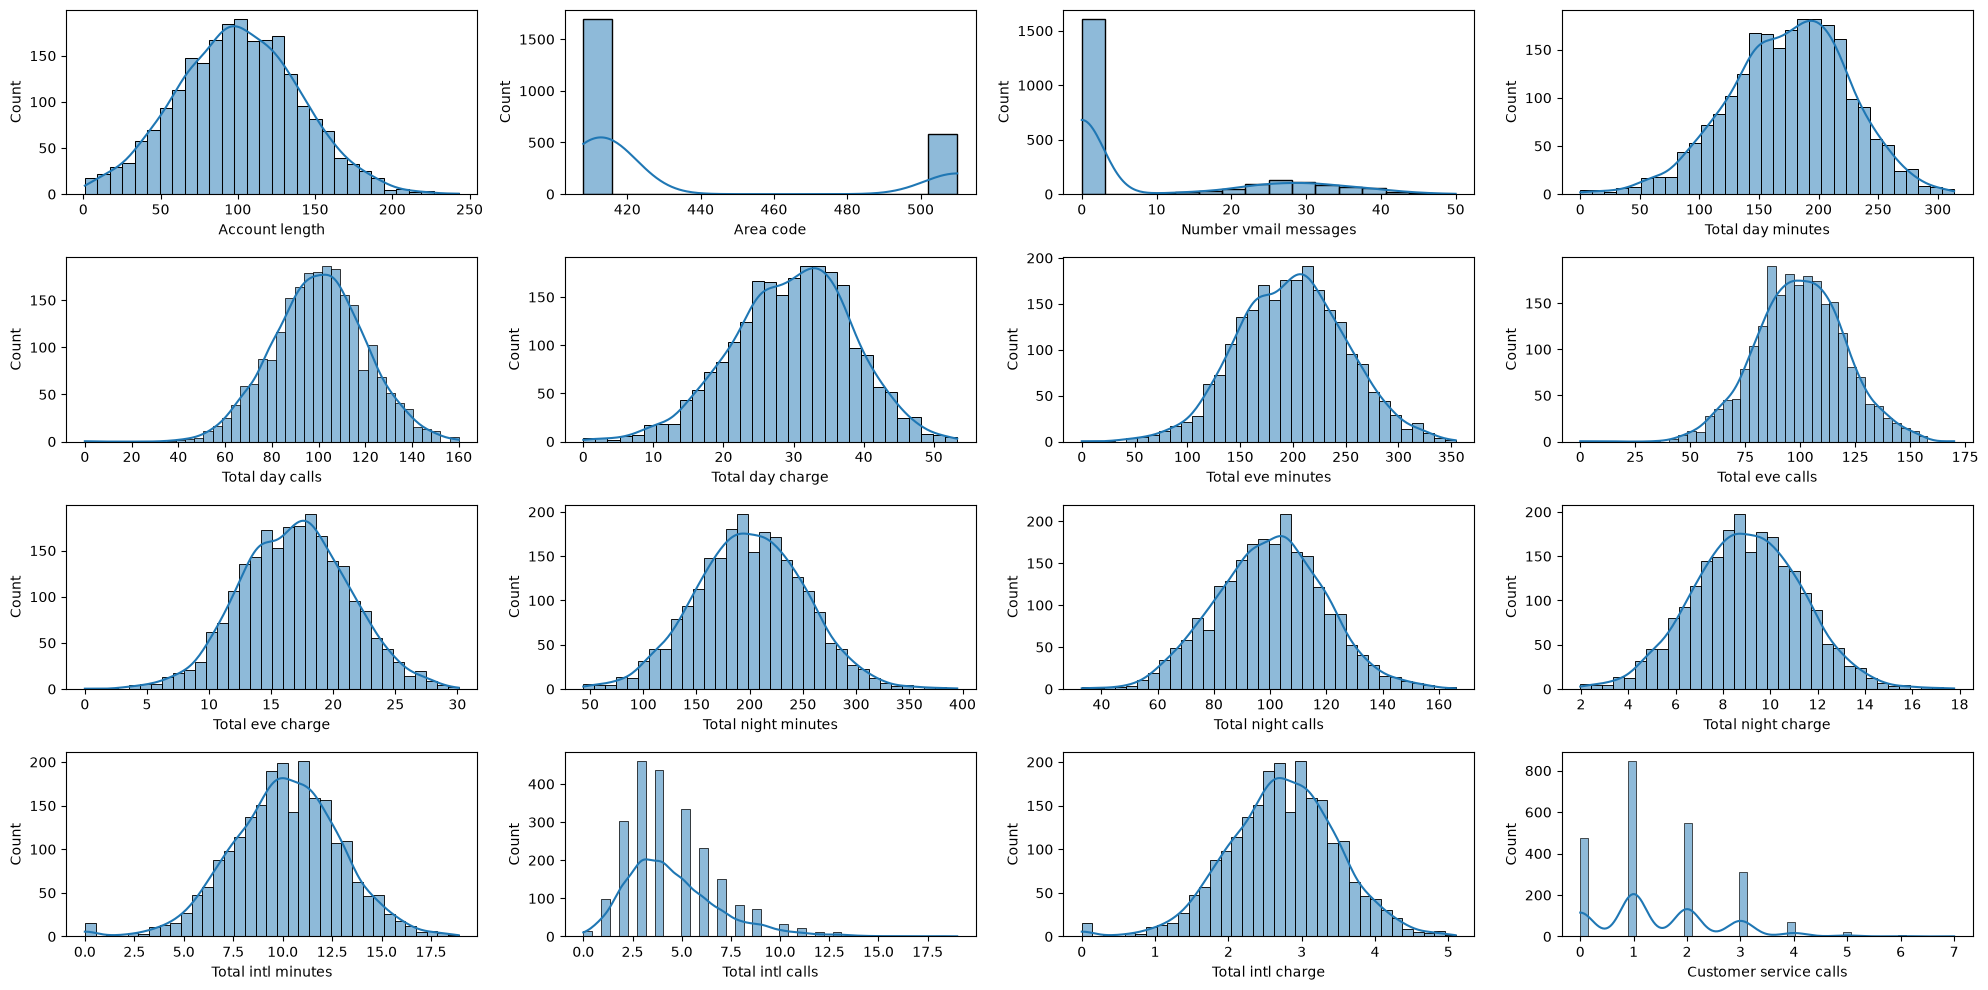

In [107]:
t = 1
for col in num:
    plt.subplot(4,4,t)
    sns.histplot(train_df[train_df['Churn']==False][col],kde=True)
    t+=1
plt.tight_layout()
plt.show()

In [108]:
for col in num:
    print(f"Skewness of {col} for those who don't churn is {round(train_df[train_df['Churn']==False][col].skew(),2)}")

Skewness of Account length for those who don't churn is 0.08
Skewness of Area code for those who don't churn is 1.11
Skewness of Number vmail messages for those who don't churn is 1.18
Skewness of Total day minutes for those who don't churn is -0.25
Skewness of Total day calls for those who don't churn is -0.06
Skewness of Total day charge for those who don't churn is -0.25
Skewness of Total eve minutes for those who don't churn is -0.02
Skewness of Total eve calls for those who don't churn is -0.07
Skewness of Total eve charge for those who don't churn is -0.02
Skewness of Total night minutes for those who don't churn is 0.03
Skewness of Total night calls for those who don't churn is 0.0
Skewness of Total night charge for those who don't churn is 0.03
Skewness of Total intl minutes for those who don't churn is -0.27
Skewness of Total intl calls for those who don't churn is 1.28
Skewness of Total intl charge for those who don't churn is -0.27
Skewness of Customer service calls for thos

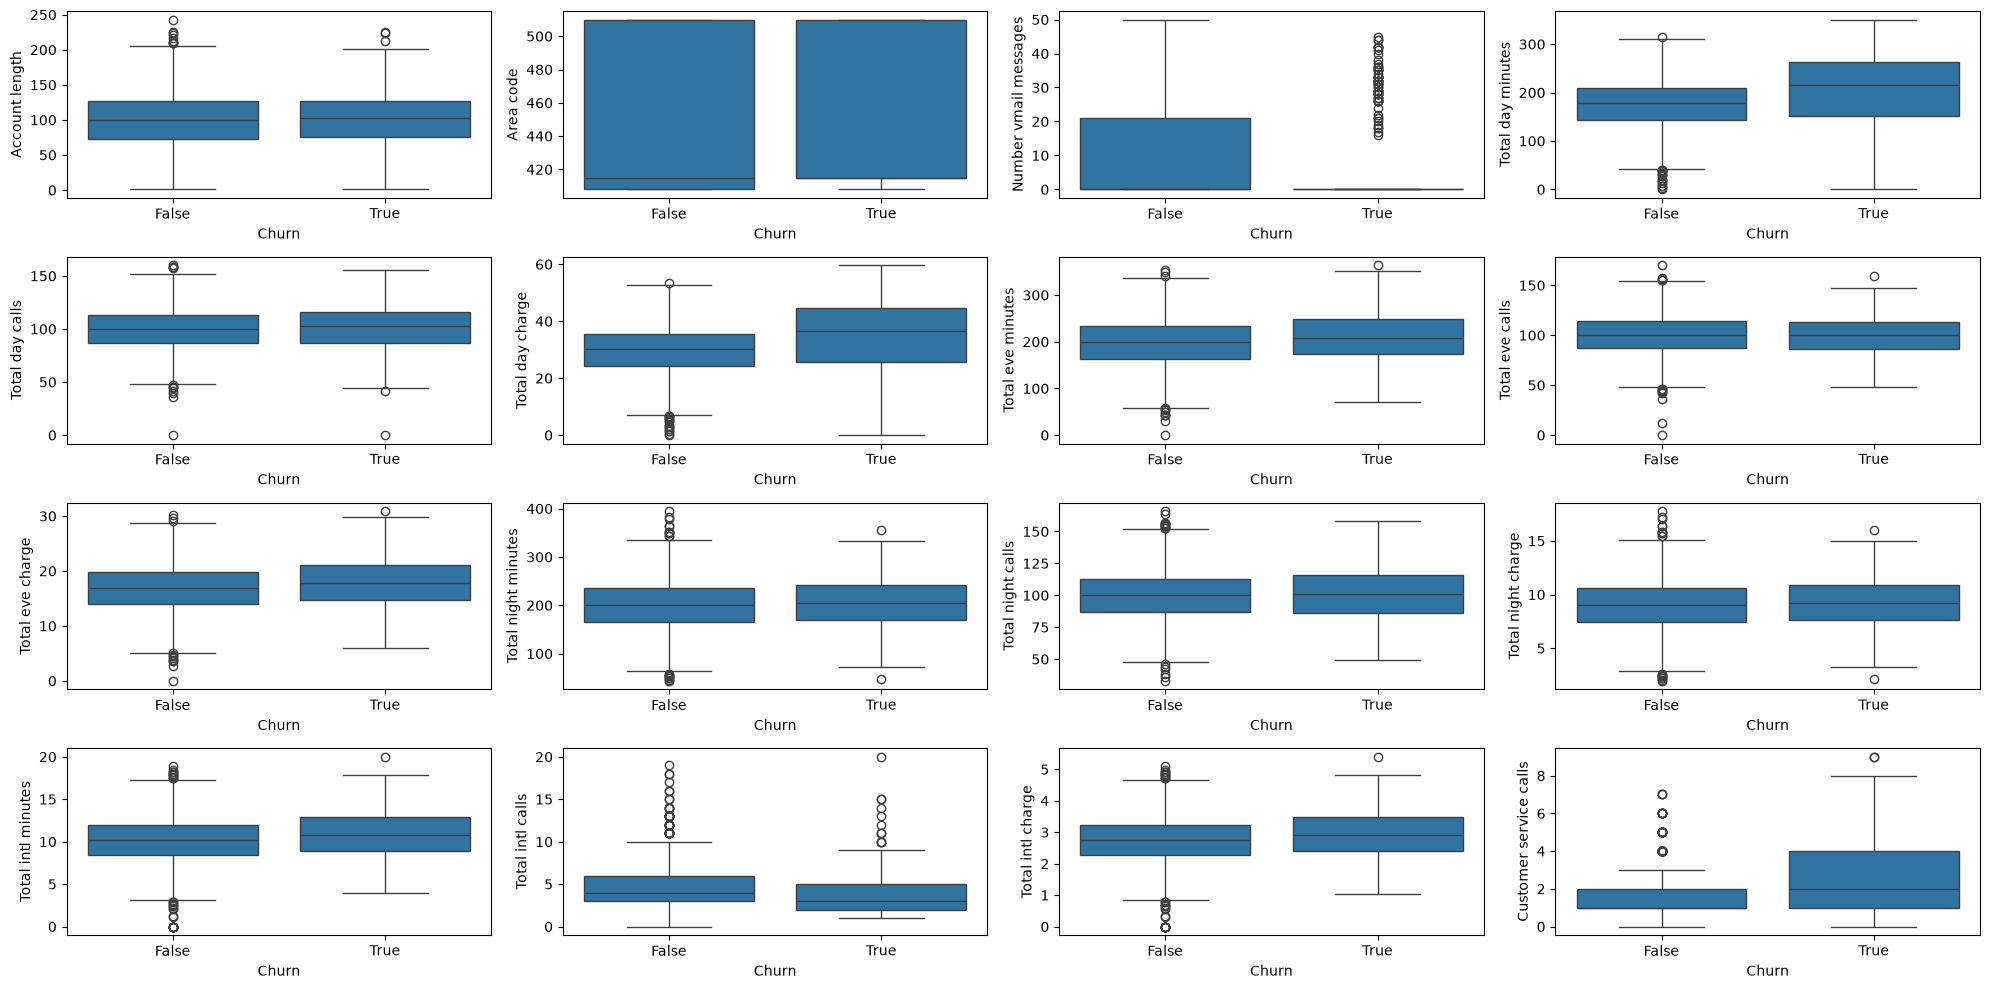

In [109]:
t = 1
for col in num:
    plt.subplot(4,4,t)
    sns.boxplot(x='Churn', y=col, data=train_df)
    t+=1
plt.tight_layout()
plt.show()

In [110]:
train_df['Churn'].value_counts(normalize=True)

Churn
False    0.854464
True     0.145536
Name: proportion, dtype: float64

In [111]:
train_df[train_df['Voice mail plan']=='No'].groupby('Voice mail plan')['Number vmail messages'].agg(['min','max'])

,min,max
Voice mail plan,,
No,0,0


In [112]:
train_df['State'].value_counts(normalize=True)

State
WV    0.033008
MN    0.026257
NY    0.025506
VA    0.025131
OH    0.024756
AL    0.024756
WY    0.024756
OR    0.023256
WI    0.022881
NV    0.022881
MD    0.022506
UT    0.022506
CO    0.022131
CT    0.022131
MI    0.021755
VT    0.021380
ID    0.021005
NC    0.021005
TX    0.020630
FL    0.020255
IN    0.020255
MT    0.019880
KS    0.019505
OK    0.019505
MA    0.019505
MO    0.019130
DE    0.019130
NJ    0.018755
GA    0.018380
SD    0.018380
ME    0.018380
SC    0.018380
RI    0.018005
WA    0.018005
MS    0.018005
AR    0.017629
AZ    0.016879
NE    0.016879
IL    0.016879
DC    0.016879
NM    0.016504
HI    0.016504
ND    0.016504
NH    0.016129
AK    0.016129
KY    0.016129
TN    0.015379
IA    0.014254
PA    0.013503
LA    0.013128
CA    0.009002
Name: proportion, dtype: float64

In [113]:
train_df['State'].nunique()

51

In [114]:
num.remove('Area code')

In [115]:
from scipy import stats
num_list = []
for col in num:
    no_churn = train_df[train_df['Churn'] == False][col]
    churn = train_df[train_df['Churn'] == True][col]
    u_stat, p_value = stats.mannwhitneyu(no_churn, churn, alternative='two-sided')
    alpha = 0.05
    if p_value < alpha:
        num_list.append(col)

In [116]:
num_list

['Number vmail messages',
 'Total day minutes',
 'Total day charge',
 'Total eve minutes',
 'Total eve charge',
 'Total intl minutes',
 'Total intl calls',
 'Total intl charge',
 'Customer service calls']

In [117]:
cat = train_df.select_dtypes(include=str).columns.tolist()

In [118]:
cat

['State', 'International plan', 'Voice mail plan']

In [119]:
from scipy.stats import chi2_contingency
cat_list = []
for col in cat:
    contingency_table = pd.crosstab(train_df[col], train_df['Churn'])
    stat, p, dof, expected = chi2_contingency(contingency_table)
    alpha = 0.05
    if p < alpha:
        cat_list.append(col)

In [120]:
cat_list

['State', 'International plan', 'Voice mail plan']

<Axes: >

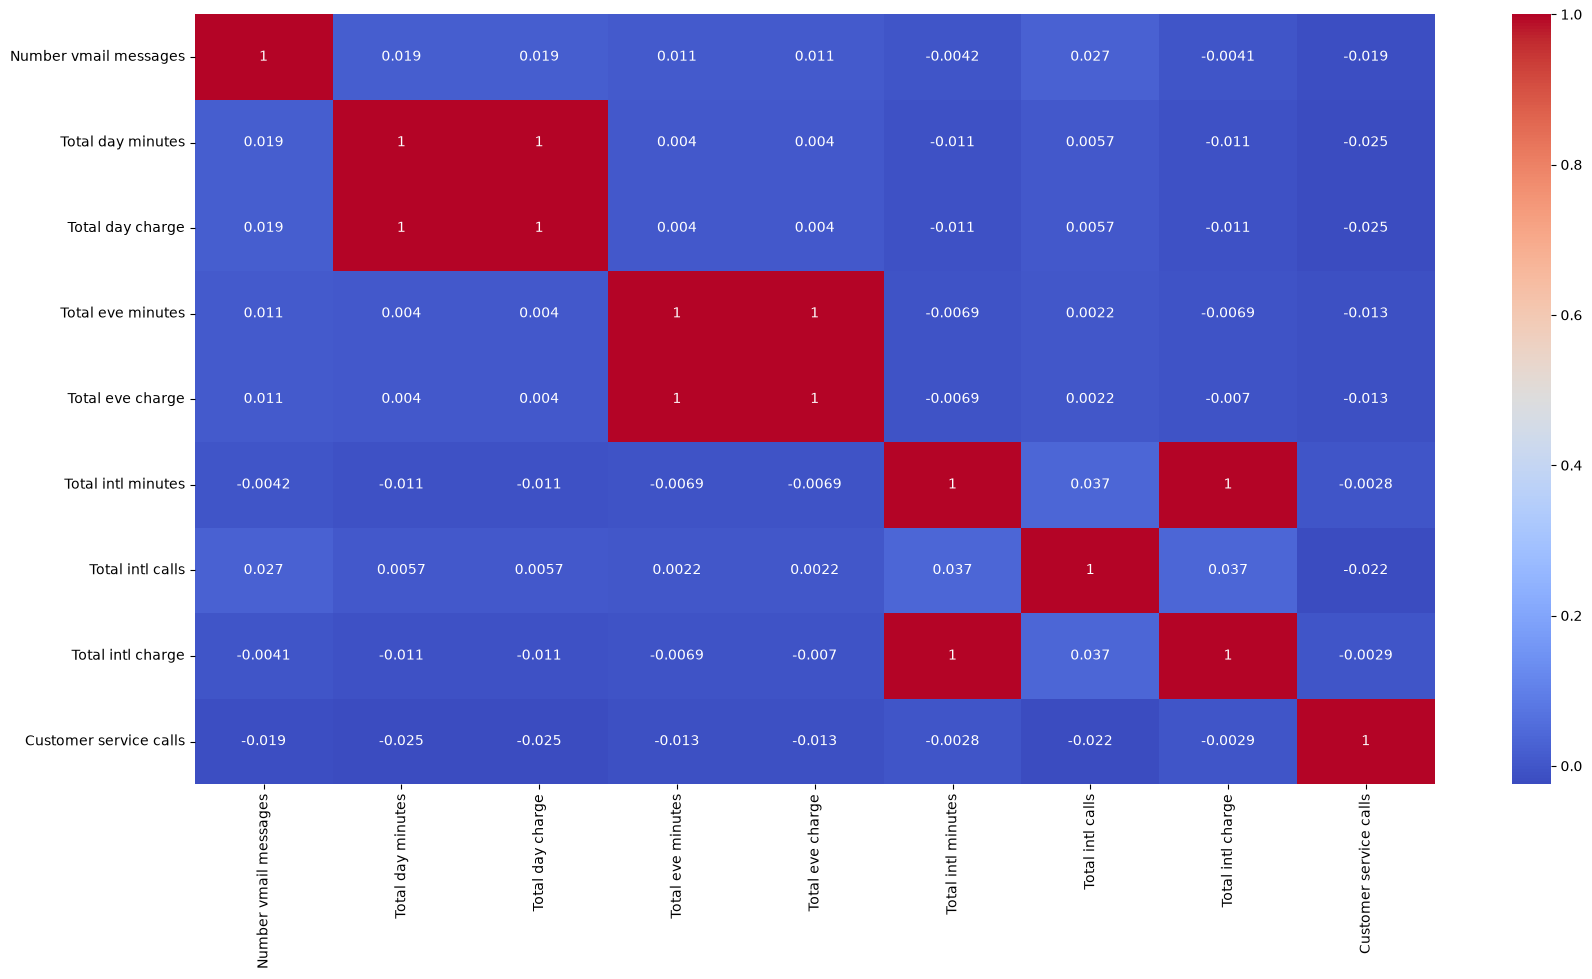

In [121]:
sns.heatmap(train_df[num_list].corr(), annot=True, cmap='coolwarm')

In [122]:
num_list.remove('Total day minutes')
num_list.remove('Total eve minutes')
num_list.remove('Total intl minutes')

In [123]:
num_list

['Number vmail messages',
 'Total day charge',
 'Total eve charge',
 'Total intl calls',
 'Total intl charge',
 'Customer service calls']

In [124]:
train_df['International plan'].value_counts(normalize=True)

International plan
No     0.898725
Yes    0.101275
Name: proportion, dtype: float64

In [125]:
train_df['Voice mail plan'].value_counts(normalize=True)

Voice mail plan
No     0.725056
Yes    0.274944
Name: proportion, dtype: float64

# Feature Engineering

In [126]:
regions = {
    'ME':'Northeast', 'NH':'Northeast', 'VT':'Northeast', 'MA':'Northeast', 'RI':'Northeast', 'CT':'Northeast', 'NY':'Northeast', 'PA':'Northeast', 'NJ':'Northeast',
    'WI':'Midwest', 'MI':'Midwest', 'IL':'Midwest', 'IN':'Midwest', 'OH':'Midwest', 'ND':'Midwest', 'SD':'Midwest', 'NE':'Midwest', 'KS':'Midwest', 'MN':'Midwest', 'IA':'Midwest', 'MO':'Midwest',
    'DE':'South', 'MD':'South', 'DC':'South', 'VA':'South', 'WV':'South', 'NC':'South', 'SC':'South', 'GA':'South', 'FL':'South', 'KY':'South', 'TN':'South', 'MS':'South', 'AL':'South', 'AR':'South', 'LA':'South', 'OK':'South', 'TX':'South',
    'ID':'West', 'MT':'West', 'WY':'West', 'NV':'West', 'UT':'West', 'CO':'West', 'AZ':'West', 'NM':'West', 'AK':'West', 'WA':'West', 'OR':'West', 'CA':'West', 'HI':'West'
}

In [127]:
train_df['Region'] = train_df['State'].map(regions)
train_df.drop(columns=['State'], inplace=True)

In [128]:
train_df.head()

,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn,Region
0,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False,Midwest
1,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False,Midwest
2,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False,Northeast
3,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False,Midwest
4,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False,South


In [129]:
processed_train_df = train_df[['Region','Number vmail messages','Total day charge','Total eve charge', 
                               'Total intl calls', 'Total intl charge', 'Customer service calls', 
                               'International plan','Churn']]

In [130]:
processed_train_df.head()

,Region,Number vmail messages,Total day charge,Total eve charge,Total intl calls,Total intl charge,Customer service calls,International plan,Churn
0,Midwest,25,45.07,16.78,3,2.70,1,No,False
1,Midwest,26,27.47,16.62,3,3.70,1,No,False
2,Northeast,0,41.38,10.30,5,3.29,0,No,False
3,Midwest,0,50.90,5.26,7,1.78,2,Yes,False
4,South,0,28.34,12.61,3,2.73,3,Yes,False


In [131]:
import os

os.makedirs('data/processed', exist_ok=True)

processed_train_df.to_csv('data/processed/train_processed.csv', index=False)